# 03 - Train macro models, v1 (baseline, no news)

**Goal:** predict this month's US CPI change (`y`, in percentage points of monthly CPI) using only macro data that is already available at the end of the month. This is a *nowcast*.

This notebook is the **baseline**. Later we add news features and check if they beat it.


**The 3 models**
1. **Linear Regression**: a weighted sum of the features. Simple and easy to read.
2. **Random Forest**: many decision trees, averaged. Can learn non-linear patterns.
3. **XGBoost**: trees built one after another, each one fixing the errors of the previous ones.

**Metrics:** RMSE (main one) and MAE, both in percentage points of monthly CPI.

**Workflow**

```
model_table_macro.csv
        |
        v
  split column ---> TRAIN (1999-2019)          TEST (2020-2023)
                       |                            |
                       v                            |
          TimeSeriesSplit cross-validation          |
          (choose hyperparameters, compare models)  |
                       |                            |
                       v                            |
          fit final pipelines on ALL train          |
                       |                            |
                       +--- only if RUN_TEST=True --+
                                        |
                                        v
                       RMSE / MAE / Diebold-Mariano on test
```

## Setup

Imports and the CONFIG cell. All team decisions live in CONFIG, so they can be changed in one place.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score, learning_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
# ---------------- CONFIG ----------------
VERSION = "v1"
RUN_TEST = True  # True runs steps 11 and 11b on the test months
SEED = 42
DROP_FEATURES = ["oil_last_chg", "gas_last_chg"]
N_SPLITS = 5
# ----------------------------------------

np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "processed_data"
print("Data folder:", DATA_DIR)

Data folder: /home/nvela/code/nvelasquez1551/can-news-nowcast-inflation/processed_data


## 1. Load the data

**What:** read the model table built in notebook 02 and the list of features.

**Why:** we need one row per month with the target `y` and the features. The `split` column (also from notebook 02) tells us which months are train and which are test.

In [3]:
df = pd.read_csv(DATA_DIR / "model_table_macro.csv", index_col="date", parse_dates=True)
print(df.shape)
df.head()

(299, 17)


,y,y_annualized,y_lag1,y_lag2,y_lag3,y_ma12,cpi_core_chg_ma12,cpi_core_chg,ppi_chg,housing_chg,payems_chg,oil_mean_chg,oil_last_chg,gas_mean_chg,gas_last_chg,exp,split
date,,,,,,,,,,,,,,,,,
1999-02-01,0.000000,0.000000,0.182315,0.182648,0.121951,0.137744,0.192021,0.113960,0.081400,-2.486004,0.081475,-3.922632,-3.981418,-1.989848,-3.147303,2.7,train
1999-03-01,0.060698,0.730813,0.000000,0.182315,0.182648,0.137744,0.177465,0.000000,-0.489397,-4.564865,0.326798,16.224188,20.956683,6.467431,17.642401,2.5,train
1999-04-01,0.665258,8.281766,0.060698,0.000000,0.182315,0.142802,0.167678,0.056931,0.244998,2.366974,0.091281,20.815565,20.800985,14.126617,4.429102,2.7,train
1999-05-01,0.060259,0.725511,0.665258,0.060698,0.000000,0.187959,0.181582,0.340909,0.812352,-9.630483,0.281121,2.074575,-7.612672,-0.035373,-1.784169,2.7,train
1999-06-01,0.000000,0.000000,0.060259,0.665258,0.060698,0.172455,0.171729,0.113379,0.886031,3.666656,0.169381,1.043617,10.979639,-1.456693,0.179856,2.8,train


In [4]:
feature_table = pd.read_csv(DATA_DIR / "feature_table.csv")
feature_table

,feature,source_series,transformation,availability_lag
0,y_lag1,CPIAUCSL,y shifted by 1 month(s),1
1,y_lag2,CPIAUCSL,y shifted by 2 month(s),2
2,y_lag3,CPIAUCSL,y shifted by 3 month(s),3
3,y_ma12,CPIAUCSL,mean of y over previous 12 months (shift(1)),1
4,cpi_core_chg_ma12,CPILFESL,mean of 100*diff(log) over previous 12 months ...,1
5,cpi_core_chg,CPILFESL,"100*diff(log(cpi_core)), shifted by 1 month(s)",1
6,ppi_chg,PPIACO,"100*diff(log(ppi)), shifted by 1 month(s)",1
7,housing_chg,HOUST,"100*diff(log(housing)), shifted by 1 month(s)",1
8,payems_chg,PAYEMS,"100*diff(log(payems)), shifted by 1 month(s)",1
9,oil_mean_chg,DCOILWTICO,"100*diff(log(oil_mean)), shifted by 0 month(s)",0


**New in v1: the `month` feature.** It is the calendar month (1 = January, 12 = December) of each row. It is not in `feature_table.csv`, so we create it here.

**Why:** our gasoline series is *not* seasonally adjusted, but the CPI target *is*. Gasoline has a normal seasonal pattern, so the same price change may mean something different depending on the month.

In [5]:
df["month"] = df.index.month
print(df["month"].value_counts().sort_index().to_dict())

{1: 24, 2: 25, 3: 25, 4: 25, 5: 25, 6: 25, 7: 25, 8: 25, 9: 25, 10: 25, 11: 25, 12: 25}


We keep the feature list in **one** variable, `FEATURES`. The next notebook can reuse everything just by adding the news columns to this list.

`y_annualized` and `split` are **never** features: the first one is the target in another unit, the second one is just a label.

In [6]:
FEATURES = [f for f in feature_table["feature"] if f not in DROP_FEATURES] + ["month"]
NUMERIC_FEATURES = [f for f in FEATURES if f != "month"]

assert "y_annualized" not in FEATURES
assert "split" not in FEATURES
print(len(FEATURES), "features:")
print(FEATURES)

13 features:
['y_lag1', 'y_lag2', 'y_lag3', 'y_ma12', 'cpi_core_chg_ma12', 'cpi_core_chg', 'ppi_chg', 'housing_chg', 'payems_chg', 'oil_mean_chg', 'gas_mean_chg', 'exp', 'month']


Now we split with the `split` column. We **never shuffle**: train is always the past, test is always the future.

In [7]:
train_df = df[df["split"] == "train"]
test_df = df[df["split"] == "test"]

X_train = train_df[FEATURES]
y_train = train_df["y"]
X_test = test_df[FEATURES]
y_test = test_df["y"]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)
print(f"Train: {train_df.index.min():%Y-%m} to {train_df.index.max():%Y-%m}")
print(f"Test:  {test_df.index.min():%Y-%m} to {test_df.index.max():%Y-%m}")

X_train: (251, 13) | y_train: (251,)
X_test:  (48, 13) | y_test:  (48,)
Train: 1999-02 to 2019-12
Test:  2020-01 to 2023-12


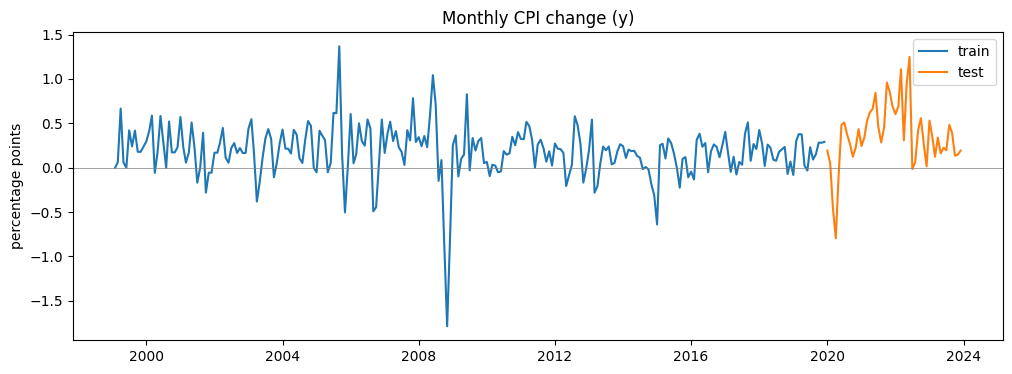

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_train.index, y_train, label="train", color="tab:blue")
ax.plot(y_test.index, y_test, label="test", color="tab:orange")
ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Monthly CPI change (y)")
ax.set_ylabel("percentage points")
ax.legend()
plt.show()

### What do we see?

- `y` is usually small and positive: around **0.2 points per month** (about 2.4% per year).
- There are a few big drops: late 2008 (oil price crash) and spring 2020 (COVID).
- The **test period is unusual**: first the COVID drop, then the 2021-2022 inflation surge, with months above 1 point. So the test is harder than most training years.

## 2. Benchmarks with no model

**What:** two very simple "predictions" that need no machine learning:
- **naive**: this month will be like last month (`y_lag1`).
- **training mean**: this month will be like the average month in train.

**Why:** a model is only useful if it beats these. We compute their errors on **train only** for now, just to get a sense of scale. (RMSE and MAE are explained in step 3.)

In [9]:
naive_train_pred = train_df["y_lag1"]

naive_train_rmse = root_mean_squared_error(y_train, naive_train_pred)
naive_train_mae = mean_absolute_error(y_train, naive_train_pred)
print(f"Naive (y_lag1)  - train RMSE: {naive_train_rmse:.4f} | MAE: {naive_train_mae:.4f}")

Naive (y_lag1)  - train RMSE: 0.3114 | MAE: 0.2226


In [10]:
train_mean = y_train.mean()
mean_train_pred = np.full(len(y_train), train_mean)

mean_train_rmse = root_mean_squared_error(y_train, mean_train_pred)
mean_train_mae = mean_absolute_error(y_train, mean_train_pred)
print(f"Training mean = {train_mean:.4f}")
print(f"Training mean   - train RMSE: {mean_train_rmse:.4f} | MAE: {mean_train_mae:.4f}")

Training mean = 0.1798
Training mean   - train RMSE: 0.2863 | MAE: 0.1921


### What do we see?

A surprise: on train, the **naive** forecast (RMSE 0.311) is **worse** than just predicting the average month (RMSE 0.286).

Monthly CPI changes are noisy and jump around, so "same as last month" is not a great guide. These two numbers give us the scale: a useful model should have an RMSE clearly below ~0.29 on train.

## 3. Metrics: MSE, RMSE and MAE

**What:** the error of one prediction is `error = actual - predicted`. We summarise many errors with:
- **MSE** (mean squared error): average of the squared errors. Big errors count a lot.
- **RMSE** = square root of MSE. Same units as `y` (percentage points of monthly CPI), so it is easy to read.
- **MAE** (mean absolute error): average of the absolute errors. Less sensitive to a few big errors.

**Why:** we need one number to compare models. Let's try a tiny example with 4 numbers, first by hand and then with sklearn.

In [11]:
y_true_example = np.array([0.2, 0.1, 0.4, 0.3])
y_pred_example = np.array([0.3, 0.1, 0.2, 0.3])

errors_example = y_true_example - y_pred_example
print("errors:        ", errors_example)
print("squared errors:", errors_example ** 2)
print("abs errors:    ", np.abs(errors_example))

errors:         [-0.1  0.   0.2  0. ]
squared errors: [0.01 0.   0.04 0.  ]
abs errors:     [0.1 0.  0.2 0. ]


In [12]:
mse_by_hand = np.mean(errors_example ** 2)
rmse_by_hand = np.sqrt(mse_by_hand)
mae_by_hand = np.mean(np.abs(errors_example))

print(f"By hand -> MSE: {mse_by_hand:.4f} | RMSE: {rmse_by_hand:.4f} | MAE: {mae_by_hand:.4f}")

By hand -> MSE: 0.0125 | RMSE: 0.1118 | MAE: 0.0750


In [13]:
mse_sklearn = mean_squared_error(y_true_example, y_pred_example)
rmse_sklearn = root_mean_squared_error(y_true_example, y_pred_example)
mae_sklearn = mean_absolute_error(y_true_example, y_pred_example)

print(f"sklearn -> MSE: {mse_sklearn:.4f} | RMSE: {rmse_sklearn:.4f} | MAE: {mae_sklearn:.4f}")

sklearn -> MSE: 0.0125 | RMSE: 0.1118 | MAE: 0.0750


### What do we see?

Both ways give the same numbers. Notice that RMSE (0.112) is bigger than MAE (0.075): the one big error (0.2) weighs more once it is squared.

**How we use the metrics in this project**
- Each model, when it learns, **minimizes squared error** internally (that is what Linear Regression, Random Forest and XGBoost with `reg:squarederror` do).
- We use **RMSE** to compare models and to choose hyperparameters, because it is in the same units as `y`.
- We also report **MAE**, as a second view that is less driven by a few big months.

## 4. Why not a random split?

**What:** to choose hyperparameters we need *validation* data inside train. Normally we would use a random K-fold.

**Why not here:** with time series, a random split would let the model learn from the future (e.g. train on 2015 and validate on 2010). That is cheating, and it makes the errors look smaller than they really are.

`TimeSeriesSplit` always trains on the past and validates on the months right after it. Each fold has a bigger train part.

In [14]:
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

fold = 1
for train_idx, val_idx in tscv.split(X_train):
    train_dates = X_train.index[train_idx]
    val_dates = X_train.index[val_idx]
    print(f"Fold {fold}: train {train_dates.min():%Y-%m} to {train_dates.max():%Y-%m} "
          f"({len(train_idx)} months) | validation {val_dates.min():%Y-%m} to {val_dates.max():%Y-%m} "
          f"({len(val_idx)} months)")
    fold = fold + 1

Fold 1: train 1999-02 to 2002-11 (46 months) | validation 2002-12 to 2006-04 (41 months)
Fold 2: train 1999-02 to 2006-04 (87 months) | validation 2006-05 to 2009-09 (41 months)
Fold 3: train 1999-02 to 2009-09 (128 months) | validation 2009-10 to 2013-02 (41 months)
Fold 4: train 1999-02 to 2013-02 (169 months) | validation 2013-03 to 2016-07 (41 months)
Fold 5: train 1999-02 to 2016-07 (210 months) | validation 2016-08 to 2019-12 (41 months)


### What do we see?

Validation is always **after** the training part, and the training part grows fold by fold. The test period (2020-2023) does not appear at all: cross-validation only uses train.

## 5. What is a Pipeline?

**What:** some models (like Linear Regression) work better when all features are on the same scale. `StandardScaler` does this: it subtracts the mean and divides by the standard deviation of each column.

**Why it matters:** the mean and std must be learned **from train only**. Let's do it step by step first.

In [15]:
X_train_numeric = X_train[NUMERIC_FEATURES]
X_test_numeric = X_test[NUMERIC_FEATURES]

scaler = StandardScaler()
scaler.fit(X_train_numeric)

X_train_scaled = scaler.transform(X_train_numeric)
X_test_scaled = scaler.transform(X_test_numeric)

print("Means learned from train (first 4 features):")
print(pd.Series(scaler.mean_, index=NUMERIC_FEATURES).head(4).round(3))

Means learned from train (first 4 features):
y_lag1    0.179
y_lag2    0.179
y_lag3    0.178
y_ma12    0.179
dtype: float64


In [16]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=NUMERIC_FEATURES, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=NUMERIC_FEATURES, index=X_test.index)

print("Train after scaling: mean and std (first 4 features)")
print(X_train_scaled.iloc[:, :4].agg(["mean", "std"]).round(3))
print()
print("Test after scaling: mean and std (first 4 features)")
print(X_test_scaled.iloc[:, :4].agg(["mean", "std"]).round(3))

Train after scaling: mean and std (first 4 features)
      y_lag1  y_lag2  y_lag3  y_ma12
mean  -0.000  -0.000  -0.000   0.000
std    1.002   1.002   1.002   1.002

Test after scaling: mean and std (first 4 features)
      y_lag1  y_lag2  y_lag3  y_ma12
mean   0.670   0.681   0.694   1.872
std    1.265   1.261   1.256   2.173


### What do we see?

Train has mean 0 and std 1 (that is how the scaler was fitted). It prints 1.002 because pandas divides by n-1 and the scaler divides by n. Test does **not**, and that is normal: test is new data that the scaler never saw.

**The leakage problem:** if we fitted the scaler on train + test together, the mean and std would contain information from the future (2020-2023). Our model would then be "helped" by data it could not have in real life. Look how different the means are:

In [17]:
leaky_scaler = StandardScaler()
leaky_scaler.fit(pd.concat([X_train_numeric, X_test_numeric]))

compare_means = pd.DataFrame({
    "mean_train_only": scaler.mean_,
    "mean_train_and_test (leaky)": leaky_scaler.mean_,
}, index=NUMERIC_FEATURES)
compare_means.round(3)

,mean_train_only,mean_train_and_test (leaky)
y_lag1,0.179,0.210
y_lag2,0.179,0.210
y_lag3,0.178,0.210
y_ma12,0.179,0.208
cpi_core_chg_ma12,0.166,0.192
cpi_core_chg,0.165,0.193
ppi_chg,0.192,0.242
housing_chg,-0.112,-0.055
payems_chg,0.069,0.069
oil_mean_chg,0.623,0.585


A **Pipeline** joins the steps (scaler + model) into one object. When we call `fit`, it fits the scaler and the model on the data we give it, and nothing else. Inside cross-validation this means: in every fold the scaler only sees that fold's training part. No leakage, and no manual work.

In [18]:
demo_pipe = make_pipeline(StandardScaler(), LinearRegression())
demo_pipe

,steps,"[('standardscaler', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [19]:
demo_pipe.fit(X_train_numeric, y_train)

pipe_scaler = demo_pipe.named_steps["standardscaler"]
print("Same means as our manual scaler?", np.allclose(pipe_scaler.mean_, scaler.mean_))

Same means as our manual scaler? True


### New in v1: treating `month` as a category

For a Linear Regression, the number 12 would mean "December is 12 times January", which makes no sense. Months are **labels**, not amounts.

`OneHotEncoder` turns `month` into one 0/1 column per month. With `drop="first"` we remove January: it becomes the baseline, and each other column means "difference compared with January".

In [20]:
month_encoder = OneHotEncoder(drop="first")
month_encoded = month_encoder.fit_transform(X_train[["month"]])

print("Columns created:", list(month_encoder.get_feature_names_out()))
print("Shape:", month_encoded.shape)

Columns created: ['month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12']
Shape: (251, 11)


We need two treatments at once: scale the numeric columns and one-hot encode `month`. `ColumnTransformer` applies each step to its own columns, and it goes inside the Pipeline like any other step.

## 6. Model 1: Linear Regression

**What:** a Pipeline with a `ColumnTransformer` (scaler for numeric columns, `OneHotEncoder(drop="first")` for `month`) and `LinearRegression()`. There are no hyperparameters to tune.

**Why:** it is the simplest model, a good first reference. We measure it with `cross_val_score` and `TimeSeriesSplit`. sklearn gives *negative* RMSE (because it always maximises scores), so we flip the sign.

In [21]:
linear_preprocess = ColumnTransformer(
    [
        ("scale", StandardScaler(), NUMERIC_FEATURES),
        ("month", OneHotEncoder(drop="first"), ["month"]),
    ],
    verbose_feature_names_out=False,
)
linear_pipe = make_pipeline(linear_preprocess, LinearRegression())

linear_scores = cross_val_score(
    linear_pipe, X_train, y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
linear_cv_rmse = -linear_scores

print("RMSE per fold:", linear_cv_rmse.round(4))
print(f"Mean CV RMSE: {linear_cv_rmse.mean():.4f}")
print(f"Std CV RMSE:  {linear_cv_rmse.std():.4f}")

RMSE per fold: [0.2262 0.1964 0.1149 0.1195 0.0955]
Mean CV RMSE: 0.1505
Std CV RMSE:  0.0512


### What do we see?

- Adding `month` lowered the mean CV RMSE from **0.183** (v0) to **0.151**, and it is better in **all 5 folds**. Step 12 shows why.
- The error still changes a lot from fold to fold: about **0.20-0.23** in the first two folds and about **0.10-0.12** in the later, calmer folds.
- The std (0.051) reminds us that the result depends on which years we validate on.

## 7. Model 2: Random Forest

**What:** a Random Forest inside a Pipeline, with a small grid of hyperparameters chosen by `GridSearchCV` + `TimeSeriesSplit`:
- `n_estimators`: number of trees.
- `max_depth`: how deep each tree can grow (deeper = more complex).
- `min_samples_leaf`: minimum months in each leaf (bigger = smoother).

**Why no scaler:** trees split on thresholds like "oil change > 3%". Changing the scale of a column does not change which split is best, so scaling is not needed.

**Why `month` stays a number here:** a tree can isolate months with splits like "month > 6", so it does not need one-hot columns.

We keep the Pipeline anyway: same structure for every model, and easy to add steps later.

In [22]:
rf_pipe = Pipeline([
    ("model", RandomForestRegressor(random_state=SEED)),
])

rf_grid = {
    "model__n_estimators": [200],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [1, 5, 10],
}
print("Combinations to try:", 1 * 3 * 3)

Combinations to try: 9


In [23]:
rf_search = GridSearchCV(
    rf_pipe,
    rf_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
rf_search.fit(X_train, y_train)

rf_cv_rmse = -rf_search.best_score_
rf_cv_std = rf_search.cv_results_["std_test_score"][rf_search.best_index_]
print("Best parameters:", rf_search.best_params_)
rf_fold_rmse = []
for k in range(N_SPLITS):
    rf_fold_rmse.append(-rf_search.cv_results_[f"split{k}_test_score"][rf_search.best_index_])

print("RMSE per fold:", np.round(rf_fold_rmse, 4))
print(f"Best CV RMSE: {rf_cv_rmse:.4f} (std {rf_cv_std:.4f})")

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
RMSE per fold: [0.2118 0.3396 0.1409 0.1281 0.1007]
Best CV RMSE: 0.1842 (std 0.0859)


### What do we see?

The best forest now has no depth limit (`max_depth=None`) and `min_samples_leaf=1`. Its CV RMSE (**0.184**) barely moved from v0 (0.187), so the `month` feature helps the forest much less than it helps the Linear Regression.

Look at fold 2 (validation 2006-2009, with the 2008 crash): **0.340**, by far its worst fold.

## 8. Model 3: XGBoost

**What:** same structure as the Random Forest, with `XGBRegressor`. New in v1: a wider grid. Like the Random Forest, it uses `month` as a number.
- `n_estimators`: number of trees.
- `max_depth`: depth of each tree (XGBoost works well with shallow trees).
- `learning_rate`: how much each new tree corrects the previous ones (smaller = slower, more careful).

**Why:** boosting often beats a Random Forest on tabular data. Let's check if that is true here.

The next cell installs `xgboost` only if it is missing.

In [24]:
try:
    import xgboost
except ImportError:
    %pip install xgboost

import xgboost
print("xgboost version:", xgboost.__version__)

xgboost version: 3.2.0


In [25]:
from xgboost import XGBRegressor

# n_jobs=1: on this tiny dataset, using all CPU cores makes XGBoost much slower
xgb_pipe = Pipeline([
    ("model", XGBRegressor(random_state=SEED, objective="reg:squarederror", n_jobs=1)),
])

xgb_grid = {
    "model__n_estimators": [100, 300, 600],
    "model__max_depth": [1, 2, 3],
    "model__learning_rate": [0.01, 0.03, 0.1],
}
print("Combinations to try:", 3 * 3 * 3)

Combinations to try: 27


In [26]:
xgb_search = GridSearchCV(
    xgb_pipe,
    xgb_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
xgb_search.fit(X_train, y_train)

xgb_cv_rmse = -xgb_search.best_score_
xgb_cv_std = xgb_search.cv_results_["std_test_score"][xgb_search.best_index_]
print("Best parameters:", xgb_search.best_params_)
xgb_fold_rmse = []
for k in range(N_SPLITS):
    xgb_fold_rmse.append(-xgb_search.cv_results_[f"split{k}_test_score"][xgb_search.best_index_])

print("RMSE per fold:", np.round(xgb_fold_rmse, 4))
print(f"Best CV RMSE: {xgb_cv_rmse:.4f} (std {xgb_cv_std:.4f})")

Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 1, 'model__n_estimators': 300}
RMSE per fold: [0.2143 0.3066 0.1237 0.1438 0.0912]
Best CV RMSE: 0.1759 (std 0.0768)


## 8b. Two small reference models (cross-validation only)

**What:** two Linear Regressions with very few features:
- `gas_mean_chg` alone.
- `gas_mean_chg` + `y_lag1`.

**Why:** they show how much of the performance comes from just one or two features, and how much the rest of the model adds.

These two are **judged by CV only**. They are never evaluated on the test set.

In [27]:
gas_pipe = make_pipeline(StandardScaler(), LinearRegression())

gas_scores = cross_val_score(
    gas_pipe, X_train[["gas_mean_chg"]], y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
gas_cv_rmse = -gas_scores

print("RMSE per fold:", gas_cv_rmse.round(4))
print(f"Mean CV RMSE: {gas_cv_rmse.mean():.4f}")
print(f"Std CV RMSE:  {gas_cv_rmse.std():.4f}")

RMSE per fold: [0.1961 0.2513 0.1266 0.1418 0.1215]
Mean CV RMSE: 0.1674
Std CV RMSE:  0.0496


In [28]:
gas_lag_pipe = make_pipeline(StandardScaler(), LinearRegression())

gas_lag_scores = cross_val_score(
    gas_lag_pipe, X_train[["gas_mean_chg", "y_lag1"]], y_train,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
)
gas_lag_cv_rmse = -gas_lag_scores

print("RMSE per fold:", gas_lag_cv_rmse.round(4))
print(f"Mean CV RMSE: {gas_lag_cv_rmse.mean():.4f}")
print(f"Std CV RMSE:  {gas_lag_cv_rmse.std():.4f}")

RMSE per fold: [0.1881 0.2252 0.1142 0.1396 0.1203]
Mean CV RMSE: 0.1575
Std CV RMSE:  0.0427


### What do we see?

- **`gas_mean_chg` alone gets 0.167.** That one feature beats the Random Forest (0.184) and XGBoost (0.176), and all 3 v0 models.
- Adding `y_lag1` improves it to **0.158**.
- The full Linear Regression (0.151) adds only a little more, and it beats `gas + y_lag1` in just 3 of the 5 folds.

So one or two features carry most of the performance. These two reference models do not use `month`.

## 9. Compare the models (train data only)

**What:** put the cross-validation RMSE of the 3 models and the 2 reference models side by side.

**Why:** this is how we choose between models **without touching the test set**.

In [29]:
cv_comparison = pd.DataFrame({
    "model": ["Linear Regression", "Random Forest", "XGBoost", "Ref: gas only", "Ref: gas + y_lag1"],
    "cv_rmse_mean": [linear_cv_rmse.mean(), rf_cv_rmse, xgb_cv_rmse,
                     gas_cv_rmse.mean(), gas_lag_cv_rmse.mean()],
    "cv_rmse_std": [linear_cv_rmse.std(), rf_cv_std, xgb_cv_std,
                    gas_cv_rmse.std(), gas_lag_cv_rmse.std()],
})
cv_comparison["version"] = VERSION
cv_comparison.round(4)

,model,cv_rmse_mean,cv_rmse_std,version
0,Linear Regression,0.1505,0.0512,v1
1,Random Forest,0.1842,0.0859,v1
2,XGBoost,0.1759,0.0768,v1
3,Ref: gas only,0.1674,0.0496,v1
4,Ref: gas + y_lag1,0.1575,0.0427,v1


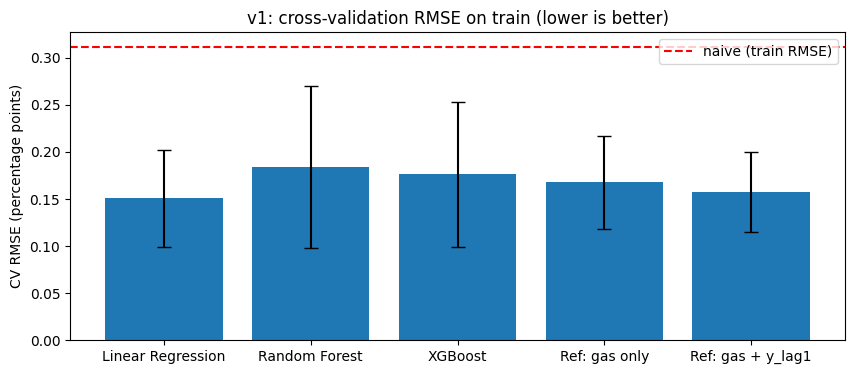

In [30]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(cv_comparison["model"], cv_comparison["cv_rmse_mean"],
       yerr=cv_comparison["cv_rmse_std"], capsize=5, color="tab:blue")
ax.axhline(naive_train_rmse, color="red", ls="--", label="naive (train RMSE)")
ax.set_ylabel("CV RMSE (percentage points)")
ax.set_title(f"{VERSION}: cross-validation RMSE on train (lower is better)")
ax.legend()
plt.show()

### What do we see?

- **Linear Regression is the best** (0.151), followed by the two reference models (0.158 and 0.167), then XGBoost (0.176) and Random Forest (0.184).
- **Two tiny linear models beat both tree models.** With about 250 months, the extra flexibility of the trees does not pay off.
- Much of the trees' gap comes from **fold 2** (validation 2006-2009): 0.340 for Random Forest and 0.307 for XGBoost, against 0.196 for Linear Regression. A likely reason: a tree can never predict outside the range of values it saw in training, while a linear model can.
- The gap is still not decisive. Linear Regression beats XGBoost in only 3 of the 5 folds, and the stds (0.04-0.09) are large.
- **Grid warning:** the best XGBoost uses `max_depth=1` (the lowest value we tried) and `learning_rate=0.1` (the highest). A better combination could be just outside the grid.

## 10. Learning curves

**What:** for each model (with its best parameters), we train on bigger and bigger parts of the training data and plot two lines:
- **training RMSE**: error on the data the model learned from.
- **validation RMSE**: error on the next months (unseen).

**How to read it**
- **Big gap** between the two lines: the model memorises the training data → **overfitting**.
- **Both lines high**: the model is too simple → **underfitting**.
- **Validation line still going down** at the right: **more data would help**.

⚠️ We only have ~250 training months, so the curves are noisy. Look at the general shape, not at small bumps.

**A detail about `TimeSeriesSplit` here:** `learning_curve` measures the training sizes on the **first** fold. With `TimeSeriesSplit`, the first fold has only 46 months, so the curve would stop at 46 months. To see the whole picture we give `learning_curve` the **last** fold of our `TimeSeriesSplit`: train 1999-2016 (210 months), validation 2016-2019. The model always trains on the oldest months first and is always validated on the same, later months.

In [31]:
best_pipelines = {
    "Linear Regression": linear_pipe,
    "Random Forest": rf_search.best_estimator_,
    "XGBoost": xgb_search.best_estimator_,
}
print(list(best_pipelines.keys()))

['Linear Regression', 'Random Forest', 'XGBoost']


In [32]:
all_folds = list(TimeSeriesSplit(N_SPLITS).split(X_train))
last_train_idx, last_val_idx = all_folds[-1]
last_fold = [(last_train_idx, last_val_idx)]

print("Learning-curve train part:", len(last_train_idx), "months")
print("Learning-curve validation:", len(last_val_idx), "months,",
      f"{X_train.index[last_val_idx].min():%Y-%m} to {X_train.index[last_val_idx].max():%Y-%m}")

Learning-curve train part: 210 months
Learning-curve validation: 41 months, 2016-08 to 2019-12


Linear Regression: validation RMSE by size [0.149 0.116 0.111 0.103 0.096]
Random Forest: validation RMSE by size [0.11  0.111 0.119 0.098 0.101]
XGBoost: validation RMSE by size [0.133 0.117 0.12  0.103 0.091]


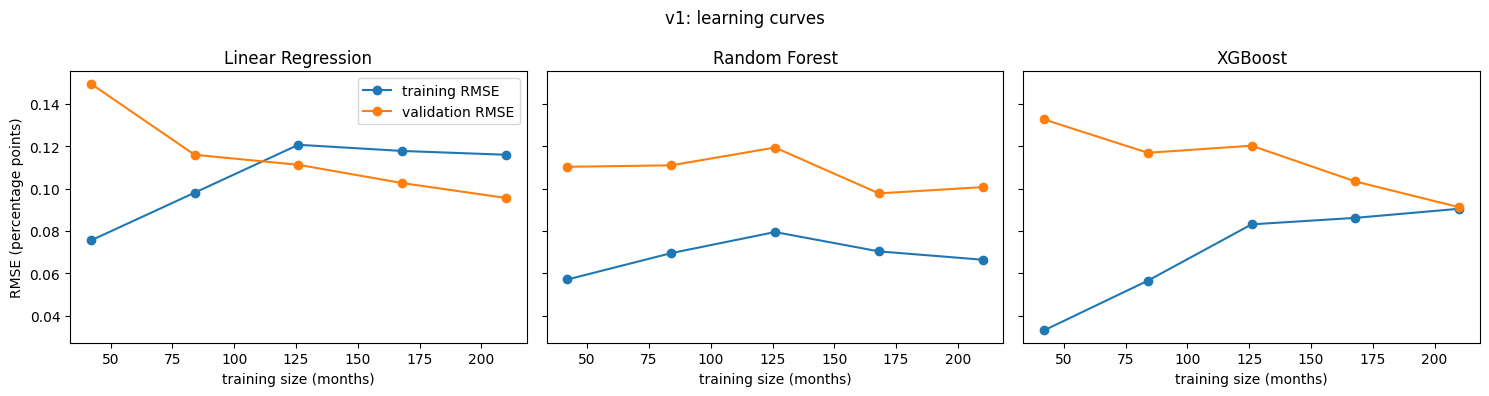

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, (name, pipe) in zip(axes, best_pipelines.items()):
    sizes, train_scores, val_scores = learning_curve(
        pipe, X_train, y_train,
        cv=last_fold,
        scoring="neg_root_mean_squared_error",
        train_sizes=np.linspace(0.2, 1.0, 5),
    )
    train_rmse = -train_scores.mean(axis=1)
    val_rmse = -val_scores.mean(axis=1)

    ax.plot(sizes, train_rmse, marker="o", label="training RMSE")
    ax.plot(sizes, val_rmse, marker="o", label="validation RMSE")
    ax.set_title(name)
    ax.set_xlabel("training size (months)")
    print(f"{name}: validation RMSE by size {val_rmse.round(3)}")

axes[0].set_ylabel("RMSE (percentage points)")
axes[0].legend()
fig.suptitle(f"{VERSION}: learning curves")
plt.tight_layout()
plt.show()

### What do we see?

- **Linear Regression:** the validation line falls steadily (0.149 to 0.096), so **more data helps**. The training line ends *above* the validation line. This is not a bug: the validation months (2016-2019) were calm, while the training months include 2008.
- **Random Forest:** a clear gap stays at 210 months (training 0.067, validation 0.101). That is **overfitting**, which makes sense for trees with no depth limit.
- **XGBoost:** the two lines meet at 210 months (both about 0.091), so there is **little overfitting**. Trees of depth 1 are very simple.
- Remember: this is one validation window with few months, so do not read too much into small bumps.

## 10b. Fit the final pipelines

**What:** fit each final pipeline on **all** the training data.

**Why:** step 12 needs these fitted models, and fitting uses train only. So this part always runs, even when `RUN_TEST=False`.

In [34]:
linear_final = clone(linear_pipe)
linear_final.fit(X_train, y_train)

rf_final = clone(rf_search.best_estimator_)
rf_final.fit(X_train, y_train)

xgb_final = clone(xgb_search.best_estimator_)
xgb_final.fit(X_train, y_train)

print("3 final pipelines fitted on", len(X_train), "training months")

3 final pipelines fitted on 251 training months


## 11. Final evaluation on the test set

> ⚠️ **This step only runs if `RUN_TEST = True` in the CONFIG.**
>
> Before switching it on, everything must be fixed: the features, the models and their hyperparameters. We do **not** go back to change anything after seeing these results.

**Important:** v0 already evaluated on these same months, and we saw those results. So this test set is no longer completely fresh, and we should keep that in mind when we report v1.

**What:** predict the test months (2020-2023) with the final pipelines from step 10b.

In [35]:
if RUN_TEST:
    test_predictions = pd.DataFrame(index=test_df.index)
    test_predictions["y"] = y_test
    test_predictions["naive_lag1"] = test_df["y_lag1"]
    test_predictions["train_mean"] = train_mean
    test_predictions["linear_macro"] = linear_final.predict(X_test)
    test_predictions["rf_macro"] = rf_final.predict(X_test)
    test_predictions["xgb_macro"] = xgb_final.predict(X_test)
    display(test_predictions.head())
else:
    print("RUN_TEST=False: test predictions skipped")

,y,naive_lag1,train_mean,linear_macro,rf_macro,xgb_macro
date,,,,,,
2020-01-01,0.191982,0.290799,0.17979,0.183563,0.140716,0.123949
2020-02-01,0.047456,0.191982,0.17979,-0.055237,-0.042036,-0.043525
2020-03-01,-0.453873,0.047456,0.17979,-0.514481,-0.192719,-0.497491
2020-04-01,-0.795168,-0.453873,0.17979,-1.039086,-0.850789,-1.063770
2020-05-01,-0.089873,-0.795168,0.17979,-0.785367,0.100167,-0.045824


We compute RMSE and MAE for the full test period, and separately for 2020-2021 (COVID) and 2022-2023 (high inflation), because these two periods are very different.

In [36]:
if RUN_TEST:
    periods = {
        "full": ("2020-01-01", "2023-12-31"),
        "2020_2021": ("2020-01-01", "2021-12-31"),
        "2022_2023": ("2022-01-01", "2023-12-31"),
    }
    model_names = {
        "naive_lag1": "Naive (y_lag1)",
        "train_mean": "Training mean",
        "linear_macro": "Linear Regression",
        "rf_macro": "Random Forest",
        "xgb_macro": "XGBoost",
    }

    rows = []
    for column, name in model_names.items():
        row = {"model": name}
        for period, (start, end) in periods.items():
            part = test_predictions.loc[start:end]
            row[f"rmse_{period}"] = root_mean_squared_error(part["y"], part[column])
            row[f"mae_{period}"] = mean_absolute_error(part["y"], part[column])
        rows.append(row)

    results = pd.DataFrame(rows)
    results["version"] = VERSION
    display(results.round(4))
else:
    print("RUN_TEST=False: test metrics skipped")

,model,rmse_full,mae_full,rmse_2020_2021,mae_2020_2021,rmse_2022_2023,mae_2022_2023,version
0,Naive (y_lag1),0.3467,0.2538,0.2852,0.2240,0.3988,0.2836,v1
1,Training mean,0.4058,0.3015,0.4210,0.3358,0.3901,0.2671,v1
2,Linear Regression,0.2093,0.1552,0.2490,0.1876,0.1600,0.1228,v1
3,Random Forest,0.2183,0.1626,0.2086,0.1590,0.2276,0.1661,v1
4,XGBoost,0.2565,0.2009,0.2573,0.2002,0.2557,0.2017,v1


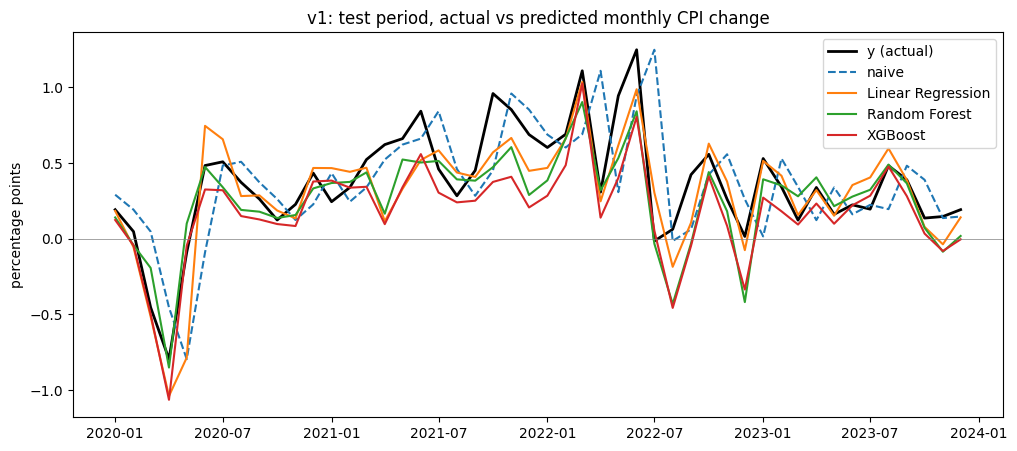

In [37]:
if RUN_TEST:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(test_predictions.index, test_predictions["y"], color="black", lw=2, label="y (actual)")
    ax.plot(test_predictions.index, test_predictions["naive_lag1"], ls="--", label="naive")
    ax.plot(test_predictions.index, test_predictions["linear_macro"], label="Linear Regression")
    ax.plot(test_predictions.index, test_predictions["rf_macro"], label="Random Forest")
    ax.plot(test_predictions.index, test_predictions["xgb_macro"], label="XGBoost")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"{VERSION}: test period, actual vs predicted monthly CPI change")
    ax.set_ylabel("percentage points")
    ax.legend()
    plt.show()
else:
    print("RUN_TEST=False: test plot skipped")

### What do we see?

*To be written by the team after the run with `RUN_TEST = True`. This notebook was built with `RUN_TEST = False`, so there are no v1 test results here yet.*

## 11b. Diebold-Mariano test

**What:** RMSE tells us which model had the smaller error on these 48 months. The Diebold-Mariano (DM) test asks if that difference is big enough to be more than luck.

**How it works**
1. For each month, compute the loss difference: `d = error_A² - error_B²` (squared loss).
2. If A and B are equally good, the mean of `d` should be close to 0.
3. `DM = mean(d) / sqrt(variance(d) / n)`. With horizon h=1 we do not need extra autocovariance terms.
4. The Harvey-Leybourne-Newbold (HLN) correction fixes the test for small samples: for h=1 it multiplies DM by `sqrt((n-1) / n)`.
5. We get the p-value from a t distribution with n-1 degrees of freedom.

A **negative** statistic means model A had the lower loss. For h=1 this is exactly a paired t-test on the squared errors, so we use that as a check.

⚠️ 48 months give low power: a large p-value does not prove that two models are equally good. And we run several tests at once, so one small p-value could appear by luck.

In [38]:
if RUN_TEST:
    comparisons = [
        ("linear_macro", "naive_lag1"),
        ("rf_macro", "naive_lag1"),
        ("xgb_macro", "naive_lag1"),
        ("rf_macro", "linear_macro"),
        ("xgb_macro", "linear_macro"),
        ("xgb_macro", "rf_macro"),
    ]

    rows = []
    for model_a, model_b in comparisons:
        error_a = test_predictions["y"] - test_predictions[model_a]
        error_b = test_predictions["y"] - test_predictions[model_b]

        d = error_a ** 2 - error_b ** 2
        n = len(d)

        dm = d.mean() / np.sqrt(d.var(ddof=0) / n)
        dm_hln = dm * np.sqrt((n - 1) / n)
        p_value = 2 * stats.t.sf(abs(dm_hln), df=n - 1)

        paired_t = stats.ttest_rel(error_a ** 2, error_b ** 2)
        assert np.isclose(dm_hln, paired_t.statistic)
        assert np.isclose(p_value, paired_t.pvalue)

        rows.append({"model_a": model_a, "model_b": model_b,
                     "dm_stat": dm_hln, "p_value": p_value})

    dm_table = pd.DataFrame(rows)
    dm_table["version"] = VERSION
    display(dm_table.round(4))
else:
    print("RUN_TEST=False: Diebold-Mariano test skipped")

,model_a,model_b,dm_stat,p_value,version
0,linear_macro,naive_lag1,-2.1593,0.0360,v1
1,rf_macro,naive_lag1,-1.8658,0.0683,v1
2,xgb_macro,naive_lag1,-1.3697,0.1773,v1
3,rf_macro,linear_macro,0.3100,0.7579,v1
4,xgb_macro,linear_macro,1.5373,0.1309,v1
5,xgb_macro,rf_macro,3.0672,0.0036,v1


## 12. Interpretation

**What:** look inside the fitted models.
- **Linear Regression coefficients**: because the numeric features are standardized inside the pipeline, each coefficient means "change in `y` when this feature goes up by 1 standard deviation", so we can compare them with each other. The `month_*` coefficients are different: each one is the difference compared with January, because those columns are 0/1.
- **Random Forest feature importances**: how much each feature helped the trees reduce the error.

⚠️ Importances show neither **direction** (up or down) nor **causality**. A coefficient is not causal either: it is a correlation, holding the other features fixed.

In [39]:
linear_model = linear_final.named_steps["linearregression"]
linear_names = linear_final.named_steps["columntransformer"].get_feature_names_out()
linear_coefs = pd.Series(linear_model.coef_, index=linear_names).sort_values()
linear_coefs.round(4)

month_3             -0.2734
month_4             -0.2297
month_5             -0.1840
month_2             -0.0703
y_lag3              -0.0065
housing_chg         -0.0033
month_6             -0.0026
y_lag2              -0.0024
cpi_core_chg        -0.0012
oil_mean_chg         0.0065
payems_chg           0.0080
month_8              0.0081
ppi_chg              0.0091
y_ma12               0.0110
cpi_core_chg_ma12    0.0127
exp                  0.0179
month_10             0.0237
month_9              0.0258
y_lag1               0.0339
month_11             0.0439
month_7              0.0522
month_12             0.0889
gas_mean_chg         0.2747
dtype: float64

In [40]:
rf_model = rf_final.named_steps["model"]
rf_importances = pd.Series(rf_model.feature_importances_, index=FEATURES).sort_values()
rf_importances.round(4)

housing_chg          0.0126
payems_chg           0.0157
cpi_core_chg_ma12    0.0158
exp                  0.0169
y_lag3               0.0187
y_lag2               0.0196
cpi_core_chg         0.0235
ppi_chg              0.0302
y_ma12               0.0303
month                0.0359
oil_mean_chg         0.0392
y_lag1               0.0666
gas_mean_chg         0.6750
dtype: float64

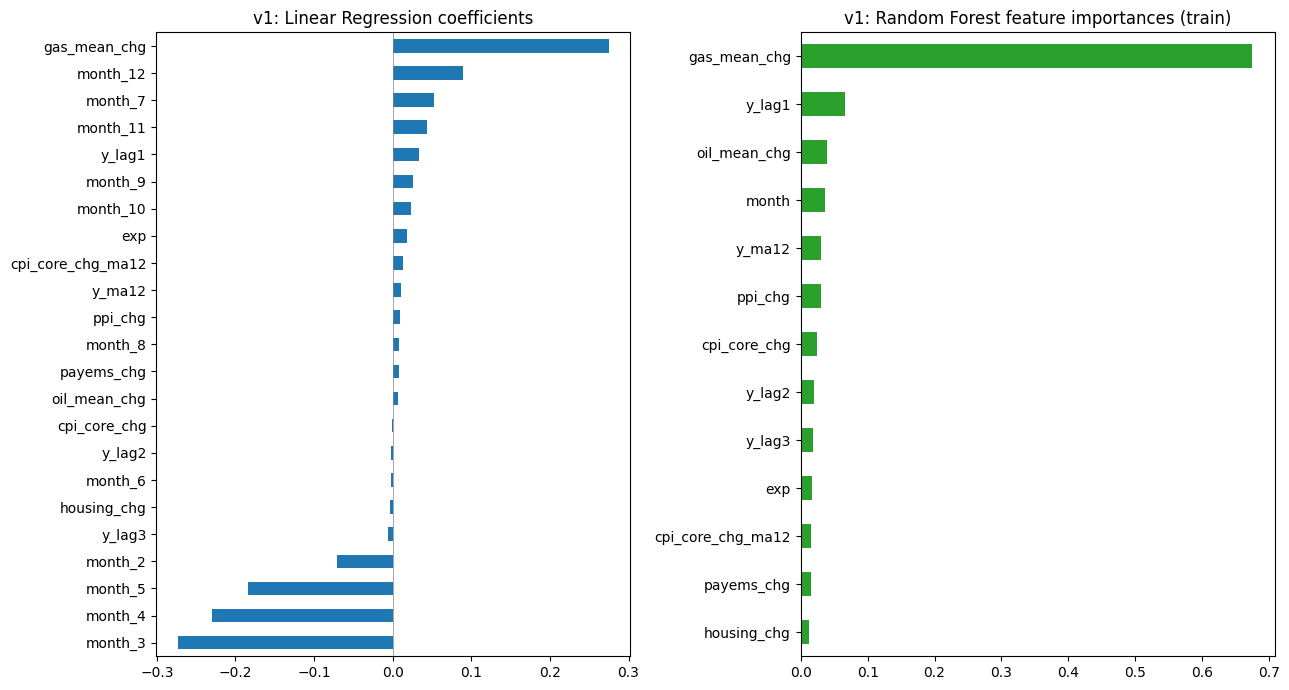

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7))

linear_coefs.plot.barh(ax=axes[0], color="tab:blue")
axes[0].axvline(0, color="grey", lw=0.5)
axes[0].set_title(f"{VERSION}: Linear Regression coefficients")

rf_importances.plot.barh(ax=axes[1], color="tab:green")
axes[1].set_title(f"{VERSION}: Random Forest feature importances (train)")

plt.tight_layout()
plt.show()

### What do we see?

- **`gas_mean_chg` is still the most important feature**: coefficient 0.27 per standard deviation, and 68% of the Random Forest importance.
- **The month effects are large.** Compared with January, March is -0.27, April is -0.23 and May is -0.18 points, holding the other features fixed.
- A likely explanation: gasoline usually gets more expensive in spring, and our gasoline series is *not* seasonally adjusted, but CPI *is*. So part of the spring price rise is "normal" and does not move seasonally adjusted CPI. The month columns correct for that. This fits the numbers, but it is an explanation, not a proof.
- This would also explain why the gasoline coefficient rose from 0.20 in v0 to 0.27 here.
- `month` has only 3.6% of the Random Forest importance.
- Be careful: gasoline and oil move together, so the Linear Regression "shares" the credit between them in a way that is not very stable. All of this comes from training data only.

## 13. Save the v1 outputs

**What:** the CV comparison and the best hyperparameters are always saved. The test files are saved only when `RUN_TEST=True`.

**Why the `v1` in the file names:** the v0 files (`model_predictions_macro.csv`, `results_macro.csv`) are never overwritten.

In [42]:
cv_path = DATA_DIR / f"cv_results_macro_{VERSION}.csv"
cv_comparison.to_csv(cv_path, index=False)
print("Saved:", cv_path.name, cv_comparison.shape)

best_params = {
    "version": VERSION,
    "rf": rf_search.best_params_,
    "xgb": xgb_search.best_params_,
}
params_path = DATA_DIR / f"best_params_macro_{VERSION}.json"
params_path.write_text(json.dumps(best_params, indent=2))
print("Saved:", params_path.name)

Saved: cv_results_macro_v1.csv (5, 4)
Saved: best_params_macro_v1.json


In [43]:
if RUN_TEST:
    predictions_out = test_predictions[["y", "naive_lag1", "linear_macro", "rf_macro", "xgb_macro"]]
    predictions_out = predictions_out.rename_axis("month").reset_index()
    predictions_out["version"] = VERSION
    predictions_out.to_csv(DATA_DIR / f"model_predictions_macro_{VERSION}.csv", index=False)
    results.to_csv(DATA_DIR / f"results_macro_{VERSION}.csv", index=False)
    dm_table.to_csv(DATA_DIR / f"dm_tests_macro_{VERSION}.csv", index=False)
    print("Saved the v1 test predictions, results and Diebold-Mariano tests")
else:
    print("RUN_TEST=False: no test files saved")

Saved the v1 test predictions, results and Diebold-Mariano tests


## 14. Summary

**What we learned from v1 (training data only)**
- Adding `month` improved the Linear Regression in all 5 folds: CV RMSE 0.183 → 0.151. It is now the best model.
- `gas_mean_chg` alone reaches 0.167, better than both tree models. One or two features carry most of the performance.
- The wider XGBoost grid reached 0.176, and its best values sit at the edge of the grid.
- The differences are noisy: the error depends a lot on the years, and fold 2 (2006-2009) is the hardest.

**What this notebook does not tell us yet**
With `RUN_TEST = False`, v1 has **no test results**. Switching it on is a team decision, once the features, models and hyperparameters are final. v0 already used these test months, so report v1 with that caveat.

**Files**
- Always saved: `cv_results_macro_v1.csv`, `best_params_macro_v1.json`.
- Saved only with `RUN_TEST = True`: `model_predictions_macro_v1.csv`, `results_macro_v1.csv`, `dm_tests_macro_v1.csv`.
- The expanding refit is now in `03b_expanding_refit_v1.ipynb`.

**Next notebook**
We add the **news features** to `FEATURES`, keep the **same months**, the **same split** and the **same 3 models**, and compare against these results. The question is simple: do the news add information beyond gasoline, the calendar month and last month's CPI?